For the first part of this assignment, we will use a popular deep learning framework called PyTorch. You will train a convolutional neural network on a 3-class subset of FashionMNIST, a simple dataset of clothing images.

**Why use a deep learning framework?**

* Your code can run on GPUs. You can use Google Colab to train much faster than on CPU. PyTorch interfaces directly with GPU hardware without requiring you to write CUDA code.
* In this class, we want you to be ready to use a deep learning framework for your project so you can experiment more efficiently than if you wrote every layer by hand.
* PyTorch makes it easier to build on standard implementations now that you understand the core mechanics of convolutional networks.
* You will also see the kind of deep learning code commonly used in research and industry.

**Note:** We will work at a high level of abstraction within PyTorch. This gives enough flexibility for the assignment, but PyTorch can do much more. If you are interested, this [tutorial](https://github.com/jcjohnson/pytorch-examples?tab=readme-ov-file) gives more background.

*Thanks to instructors from Stanford's CS231n, including Prof. Fei-Fei Li, Prof. Ranjay Krishna, and Prof. Justin Johnson, for ideas and starter code.*

## Helper file

The starter bundle includes `pytorch_training.py`, which mirrors selected implementation TODOs from this notebook for staff-side checks. Complete the notebook first; if your Gradescope instructions ask for the helper file, copy the same implementations there. The notebook and PDF are still required for training results, plots, and discussion.


In [20]:
import torch
import torch.nn as nn
import torchvision
import torchvision.transforms as T
from torch.utils.data import Dataset, DataLoader
import numpy as np
from PIL import Image

In [91]:
import math
import matplotlib.pyplot as plt
import re, os

from matplotlib.ticker import MaxNLocator


In [21]:
USE_GPU = True
dtype = torch.float32 # We will be using float throughout.

if USE_GPU and torch.cuda.is_available():
    device = torch.device('cuda')
else:
    device = torch.device('cpu')

## Working with Data

PyTorch offers dataloaders to handle datasets easily. Here is a Dataset class written for the FashionMNIST dataset. Note the two required functions: `__len__()` that gives the length of the dataset and `__getitem__()` which retrieves a specific image and its annotation.

For each image in this 3-class FashionMNIST subset, we are interested in the type of clothing item (stored in `labels`) that we're using as the target variable for our analysis. `__getitem__()` returns this annotation as well as the image itself. Also note the transform - we convert the image to a form that we want to work with. Typically, we want the image to be a **`tensor`**, which is similar to a numpy array.


In [ ]:
FASHION_CLASS_IDS = [0, 1, 2]
FASHION_CLASS_NAMES = ['T-shirt/top', 'Trouser', 'Pullover']


def get_transform(split='train'):
    return T.Compose(
        [
            T.ToTensor(),
            T.Normalize((0.5,), (0.5,)),
        ]
    )


def get_dataset(split='train', transform=None):
    full_dataset = torchvision.datasets.FashionMNIST(
        'data',
        train=split == 'train',
        download=False,
        transform=transform if transform is not None else T.ToTensor(),
    )
    targets = np.array(full_dataset.targets)
    indices = np.flatnonzero(np.isin(targets, FASHION_CLASS_IDS))
    return torch.utils.data.Subset(full_dataset, indices)


def get_dataloaders(batch_size=64, num_workers=2):
    '''Use PyTorch torch.utils.data.DataLoader to load batched data'''
    train_dataset = get_dataset('train', get_transform())
    val_dataset = get_dataset('val', get_transform())
    train_dataloader = torch.utils.data.DataLoader(
        train_dataset,
        batch_size=batch_size,
        shuffle=True,  # shuffle training set
        num_workers=num_workers,  # turns on multi-processing loading so training is not blocked by data loading
        pin_memory=True,  # pin_memory allows faster transfer from CPU to GPU
    )
    val_dataloader = torch.utils.data.DataLoader(
        val_dataset,
        batch_size=batch_size,
        shuffle=False,
        num_workers=num_workers,
        pin_memory=True,
    )
    return train_dataloader, val_dataloader

print('training set size:	{}'.format(len(get_dataset('train'))))
print('validation set size:	{}'.format(len(get_dataset('val'))))
print('classes:	{}'.format(FASHION_CLASS_NAMES))

# Each element yielded by `train_loader` (a Python iterable) is still a 2-tuple,
# but now consisting of a batched image tensor, and a batched label tensor.
train_loader, val_loader = get_dataloaders()
images, labels = next(iter(train_loader))

print('batched image tensor shape: {}'.format(images.shape))
print('batched label tensor shape: {}'.format(labels.shape))


training set size:	18000
validation set size:	3000
classes:	['T-shirt/top', 'Trouser', 'Pullover']
batched image tensor shape: torch.Size([64, 1, 28, 28])
batched label tensor shape: torch.Size([64])


## Problem 1. PyTorch Sequential API

PyTorch provides a container Module called `nn.Sequential`, which allows us to construct simple, feedforward networks. It is not as flexible as other methods, but is sufficient for our case.


### Sequential API: Two-Layer Network
Let's see how to write a simple two-layer fully connected network example with `nn.Sequential`, and train it.
You don't need to tune any hyperparameters here, but you should achieve above 75% accuracy after one epoch of training.

In [58]:
# This function converts N 3 dimentional images to a one dimensional vector per image
def flatten(x):
    N = x.shape[0]
    return x.view(N, -1)

# We need to wrap `flatten` function in a module in order to stack it in nn.Sequential
class Flatten(nn.Module):
    def forward(self, x):
        return flatten(x)

hidden_layer_size = 100
learning_rate = 5e-4


# This creates a model that has 2 linear layers with a hidden layer size of 100.
# Notice that we first flatten our images
model = nn.Sequential(
    Flatten(),
    nn.Linear(1 * 28 * 28, hidden_layer_size),
    nn.ReLU(),
    nn.Linear(hidden_layer_size, 3),
)


# optim has different optimizers you can try! This is set to SGD + momentum, but you can use Adam or
# RMSprop as examples. See https://pytorch.org/docs/stable/optim.html

optimizer = torch.optim.SGD(model.parameters(), lr=learning_rate, momentum=0.9)

Here is a simple function that trains a model using PyTorch. Notice how PyTorch automatically creates a computation graph for backpropagation. You do not need to fill in any code here.

In [24]:
def train(model, optimizer, loader_train, loader_val, epochs=1, print_every=10):
    """
    Train a model using the PyTorch Module API.

    Inputs:
    - model: A PyTorch Module giving the model to train.
    - optimizer: An Optimizer object we will use to train the model
    - loader_train: A dataloader containing the train dataset
    - loader_val: A dataloader containing the validation dataset
    - epochs: (Optional) An integer giving the number of epochs to train for
    - print_every: (Optional) An integer specifying how often to print the loss.

    Returns: Nothing, but prints model losses and accuracies during training.
    """
    model = model.to(device=device)  # move the model parameters to CPU/GPU
    for e in range(epochs):
        for t, (x, y) in enumerate(loader_train):
            model.train()  # put model to training mode
            x = x.to(device=device, dtype=dtype)  # move to device, e.g. GPU
            y = y.to(device=device, dtype=torch.long)

            scores = model(x)
            loss = torch.nn.functional.cross_entropy(scores, y)

            # Zero out all of the gradients for the variables which the optimizer
            # will update.
            optimizer.zero_grad()

            # This is the backwards pass: compute the gradient of the loss with
            # respect to each  parameter of the model.
            loss.backward()

            # Actually update the parameters of the model using the gradients
            # computed by the backwards pass.
            optimizer.step()

            if t % print_every == 0:
                print('Epoch {}, iteration {}, loss = {}'.format(e, t, loss.item()))


        print('Epoch {} done'.format(e))
        check_accuracy(loader_val, model)


In [25]:

def check_accuracy(loader, model):
    """
    Finds the accuracy of a model

    Inputs:
    - loader: A dataloader containing the validation / testing dataset
    - model: A PyTorch Module giving the model to evaluate.

    Returns: Nothing, but prints the accuracy.
    """

    num_correct = 0
    num_samples = 0
    model.eval()  # set model to evaluation mode

    with torch.no_grad(): # no need to store computation graph or local gradients
        for x, y in loader:
            x = x.to(device=device, dtype=dtype)  # move to device, e.g. GPU
            y = y.to(device=device, dtype=torch.long)
            scores = model(x)
            _, preds = scores.max(1)
            num_correct += (preds == y).sum()
            num_samples += preds.size(0)

        acc = float(num_correct) / num_samples
        print('Got %d / %d correct (%.2f)' % (num_correct, num_samples, 100 * acc))


In [26]:
train(model, optimizer, train_loader, val_loader)

Epoch 0, iteration 0, loss = 1.0801774263381958
Epoch 0, iteration 10, loss = 1.0020962953567505
Epoch 0, iteration 20, loss = 0.8657204508781433
Epoch 0, iteration 30, loss = 0.821173906326294
Epoch 0, iteration 40, loss = 0.7360575199127197
Epoch 0, iteration 50, loss = 0.5946977138519287
Epoch 0, iteration 60, loss = 0.5617590546607971
Epoch 0, iteration 70, loss = 0.5466914176940918
Epoch 0, iteration 80, loss = 0.4706866443157196
Epoch 0, iteration 90, loss = 0.39777708053588867
Epoch 0, iteration 100, loss = 0.3761046528816223
Epoch 0, iteration 110, loss = 0.2940293550491333
Epoch 0, iteration 120, loss = 0.27921125292778015
Epoch 0, iteration 130, loss = 0.22956573963165283
Epoch 0, iteration 140, loss = 0.3279736042022705
Epoch 0, iteration 150, loss = 0.31338319182395935
Epoch 0, iteration 160, loss = 0.20714376866817474
Epoch 0, iteration 170, loss = 0.23438742756843567
Epoch 0, iteration 180, loss = 0.2862119674682617
Epoch 0, iteration 190, loss = 0.15724633634090424
Epoch

### 1a. Sequential API: 3-layer ConvNet

Use `nn.Sequential` to define and train a three-layer ConvNet with this architecture.
Hint: Look up https://pytorch.org/docs/stable/generated/torch.nn.Conv2d.html and https://pytorch.org/docs/stable/generated/torch.nn.MaxPool2d.html#torch.nn.MaxPool2d

1. Convolutional layer (with bias) with 32 5x5 filters, with zero-padding of 2
2. ReLU
3. Convolutional layer (with bias) with 16 3x3 filters, with zero-padding of 1
4. ReLU
5. MaxPool (filter size 2, stride 2)
6. Fully-connected layer (with bias) to compute scores for 3 classes

You can use the default PyTorch weight initialization.

You should optimize your model using stochastic gradient descent with momentum 0.9.

You do not need to tune any hyperparameters but you should see accuracy above 78% after one epoch of training.


In [59]:
channel_1 = 32
channel_2 = 16
learning_rate = 7.5e-4

model = nn.Sequential(
    nn.Conv2d(in_channels=1, out_channels=channel_1, kernel_size = 5, padding=2),
    nn.ReLU(),
    nn.Conv2d(in_channels=channel_1, out_channels=channel_2, kernel_size = 3, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(kernel_size=2, stride=2),
    Flatten(),
    nn.Linear(in_features=channel_2*14*14, out_features=3, bias=True)
)


optimizer = torch.optim.SGD(model.parameters(), lr=learning_rate, momentum=0.9)


################################################################################


train(model, optimizer, train_loader, val_loader, print_every=100)

Epoch 0, iteration 0, loss = 1.1165982484817505
Epoch 0, iteration 100, loss = 0.2074056714773178
Epoch 0 done
Got 2810 / 3000 correct (93.67)


In [60]:
torch.save(transformer.state_dict(), 'original.pth')

### 1b. Open-ended challenge

Now it is your turn. Design and train a network that gets over **90% accuracy on the validation set** within **5 epochs**. You may experiment with different architectures, such as increasing depth, changing the number or size of filters, changing the optimizer, adding data augmentation, or using other reasonable training changes.

**Deliverable:** In the space below, describe what you did. Include your model architecture, optimizer, and all hyperparameters. Also plot the training loss across iterations. You may modify the provided `train()` function to return loss values.

You can save your model with:

```python
torch.save(model.state_dict(), PATH)
```

In [105]:
def train_with_history(model, optimizer, loader_train, loader_val, loader_test=None, 
                       epochs=1, print_every=10):
    
    model = model.to(device=device)

    train_losses = []
    train_accuracies = []
    val_accuracies = []
    test_accuracies = []

    for e in range(epochs):
        total_loss = 0
        correct = 0
        total = 0

        for t, (x, y) in enumerate(loader_train):
            model.train()
            x = x.to(device=device, dtype=dtype)
            y = y.to(device=device, dtype=torch.long)

            scores = model(x)
            loss = torch.nn.functional.cross_entropy(scores, y)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            total_loss += loss.item() * x.size(0)
            correct += (scores.argmax(dim=1) == y).sum().item()
            total += x.size(0)

            if t % print_every == 0:
                print('Epoch {}, iteration {}, loss = {}'.format(e, t, loss.item()))

        train_losses.append(total_loss / total)
        train_accuracies.append(correct / total * 100)

        print('Epoch {} done'.format(e))

        # --- Validation ---
        model.eval()
        val_correct = 0
        val_total = 0
        with torch.no_grad():
            for x, y in loader_val:
                x = x.to(device=device, dtype=dtype)
                y = y.to(device=device, dtype=torch.long)
                scores = model(x)
                val_correct += (scores.argmax(dim=1) == y).sum().item()
                val_total += x.size(0)
        val_accuracies.append(val_correct / val_total * 100)

        # --- Test (if provided) ---
        if loader_test is not None:
            test_correct = 0
            test_total = 0
            with torch.no_grad():
                for x, y in loader_test:
                    x = x.to(device=device, dtype=dtype)
                    y = y.to(device=device, dtype=torch.long)
                    scores = model(x)
                    test_correct += (scores.argmax(dim=1) == y).sum().item()
                    test_total += x.size(0)
            test_accuracies.append(test_correct / test_total * 100)

        # Print results for the epoch
        if loader_test is not None:
            print(f"Train Loss: {train_losses[-1]:.4f}, "
                  f"Train Acc: {train_accuracies[-1]:.2f}%, "
                  f"Val Acc: {val_accuracies[-1]:.2f}%, "
                  f"Test Acc: {test_accuracies[-1]:.2f}%")
        else:
            print(f"Train Loss: {train_losses[-1]:.4f}, "
                  f"Train Acc: {train_accuracies[-1]:.2f}%, "
                  f"Val Acc: {val_accuracies[-1]:.2f}%")

    if loader_test is not None:
        return train_losses, train_accuracies, val_accuracies, test_accuracies
    return train_losses, train_accuracies, val_accuracies

In [62]:
def conv2d_model():
    # conv 2d
    return nn.Sequential(
        nn.Conv2d(1, channel_1, kernel_size=7, padding=2), nn.ReLU(),
        nn.Conv2d(channel_1, channel_2, kernel_size=5, padding=2), nn.ReLU(),
        nn.Conv2d(channel_2, channel_2, kernel_size=5, padding=2), nn.ReLU(),
        nn.Conv2d(channel_2, channel_2, kernel_size=3, padding=1), nn.ReLU(),
        nn.MaxPool2d(kernel_size=2, stride=2),
        Flatten(),
        nn.LazyLinear(3),
    )

In [ ]:
# TODO (1b): Train a Sequential ConvNet.
model = conv2d_model()

optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

train_losses, train_acc, val_acc = train_with_history(model, optimizer, train_loader, val_loader, epochs=5, print_every=100 )

torch.save(model.state_dict(), 'open_ended_cnn.pth')  ## save a model to open_ended_cnn.pth

c:\Users\elean\miniconda3\envs\cos429\Lib\site-packages\torch\nn\modules\lazy.py:181: UserWarning: Lazy modules are a new feature under heavy development so changes to the API or functionality can happen at any moment.
  warnings.warn('Lazy modules are a new feature under heavy development '


Epoch 0, iteration 0, loss = 1.0999951362609863
Epoch 0, iteration 100, loss = 0.05915118381381035
Epoch 0, iteration 200, loss = 0.19701962172985077
Epoch 0 done
Train Loss: 0.1504, Train Acc: 94.72%, Val Acc: 96.77%
Epoch 1, iteration 0, loss = 0.05191575363278389
Epoch 1, iteration 100, loss = 0.08485303819179535
Epoch 1, iteration 200, loss = 0.2513062357902527
Epoch 1 done
Train Loss: 0.0795, Train Acc: 97.44%, Val Acc: 97.33%
Epoch 2, iteration 0, loss = 0.029868170619010925
Epoch 2, iteration 100, loss = 0.06883230805397034
Epoch 2, iteration 200, loss = 0.14222049713134766
Epoch 2 done
Train Loss: 0.0684, Train Acc: 97.72%, Val Acc: 96.83%
Epoch 3, iteration 0, loss = 0.07764542102813721
Epoch 3, iteration 100, loss = 0.029152149334549904
Epoch 3, iteration 200, loss = 0.021120211109519005
Epoch 3 done
Train Loss: 0.0633, Train Acc: 97.84%, Val Acc: 97.67%
Epoch 4, iteration 0, loss = 0.01607493683695793
Epoch 4, iteration 100, loss = 0.09267779439687729
Epoch 4, iteration 200,

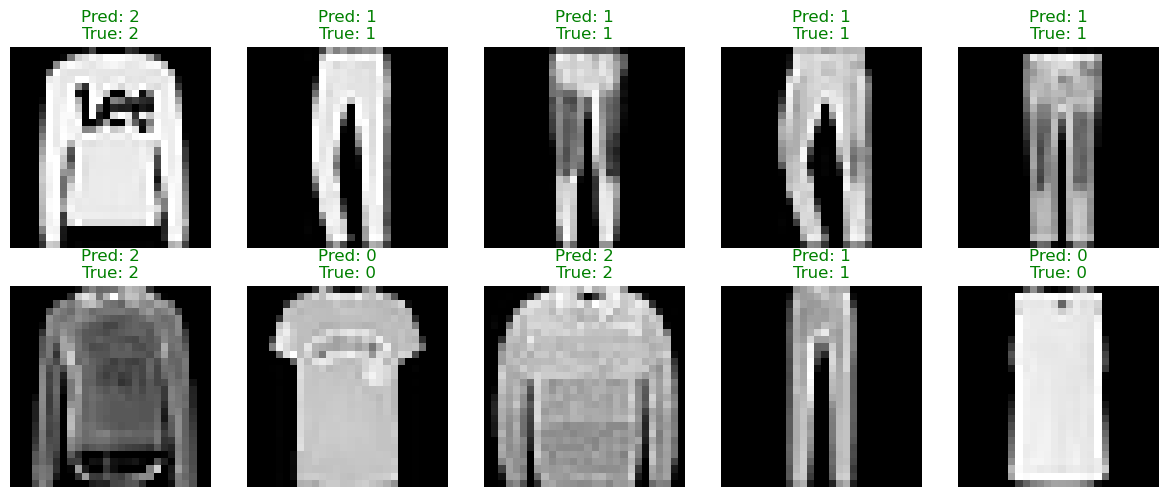

In [30]:
import torch
import matplotlib.pyplot as plt

# Load trained weights
model.load_state_dict(
    torch.load("model.pth", map_location="cpu", weights_only=True)
)
model.eval()

images, labels = next(iter(val_loader))

device = next(model.parameters()).device

with torch.no_grad():
    outputs = model(images.to(device))
    predictions = outputs.argmax(dim=1).cpu()

fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for i, ax in enumerate(axes.flat):
    ax.imshow(images[i, 0], cmap="gray")
    ax.set_title(
        f"Pred: {predictions[i].item()}\nTrue: {labels[i].item()}",
        color="green" if predictions[i] == labels[i] else "red"
    )
    ax.axis("off")

plt.tight_layout()
plt.show()


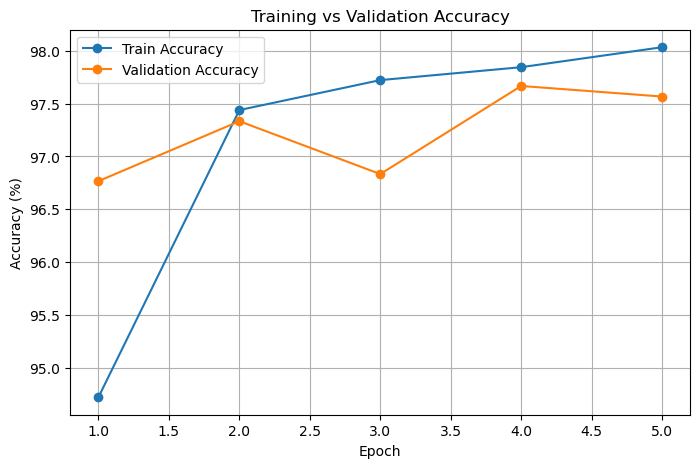

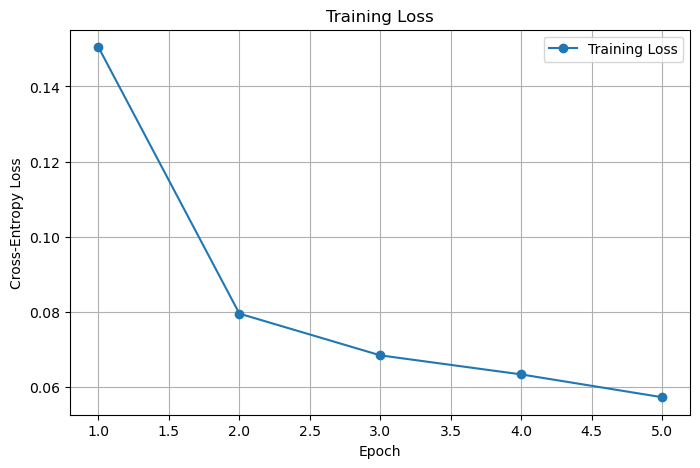

In [31]:
import matplotlib.pyplot as plt

epochs = range(1, len(train_losses) + 1)

# Accuracy plot
plt.figure(figsize=(8, 5))
plt.plot(epochs, train_acc, marker='o', label='Train Accuracy')
plt.plot(epochs, val_acc, marker='o', label='Validation Accuracy')

plt.xlabel('Epoch')
plt.ylabel('Accuracy (%)')
plt.title('Training vs Validation Accuracy')
plt.legend()
plt.grid(True)
plt.show()

# Loss plot
plt.figure(figsize=(8, 5))
plt.plot(epochs, train_losses, marker='o', label='Training Loss')

plt.xlabel('Epoch')
plt.ylabel('Cross-Entropy Loss')
plt.title('Training Loss')
plt.legend()
plt.grid(True)
plt.show()


In [32]:
# Suppose your model is the 2-layer fully connected network we defined initially. In that case, do the
# following to load the parameter values into the model.
#
# TODO: switch this to your own architecture before loading your saved model.
# model = nn.Sequential(
#     Flatten(),
#     nn.Linear(1 * 28 * 28, hidden_layer_size),
#     nn.ReLU(),
#     nn.Linear(hidden_layer_size, 3),
# )
# model.load_state_dict(torch.load('model.pth', map_location=device))


TODO 1b: Describe the changes you made to the model, including hyperparameters. Plot the training loss.  

I noticed that having a greater kernel helps increase accuracy. At first, I was inspired by the ResNet that only had 3x3 kernels,s and the accuracy was around 25%. However, once I added a 7x7 kernel, the accuracy improved.
I also decided to use an Adam optimizer instead of the momentum one. The adam optimizer combines both RMSprop and momentum, making it a more powerful optimizer.I used the same learning rate as the original one, and it was a pretty good one, because it did not undertrain or overshoot. In fact the loss plot looked pretty good.

In [ ]:
from torch.utils.data import random_split, DataLoader

# 1. Get the 18,000 training images
full_train = get_dataset('train', get_transform())

# 2. Split them into 80% Train and 20% Val
train_size = int(0.8 * len(full_train))
val_size = len(full_train) - train_size
train_subset, val_subset = random_split(full_train, [train_size, val_size])

# 3. Redefine your loaders
train_loader = DataLoader(train_subset, batch_size=128, shuffle=True, num_workers=2)
val_loader = DataLoader(val_subset, batch_size=128, shuffle=False, num_workers=2)

In [150]:
def run_one_sweep(lr, model_fn=conv2d_model, epochs=5, save_dir="good_model_data", model_name="cnn"):
    """
    Trains a single model for ONE learning rate.
    Saves the model and history, including test accuracy.
    Resumable: skips if already trained and saved.
    """
    os.makedirs(save_dir, exist_ok=True)
    
    print(f"\n----- {model_name} | lr = {lr:.0e} -----")
    
    model_path = f"{save_dir}/{model_name}_lr_{lr:.0e}.pth"
    hist_path  = f"{save_dir}/hist_{model_name}_lr_{lr:.0e}.pth"

    # Check if alr exists
    if os.path.exists(model_path) and os.path.exists(hist_path):
        print(f"[skip] {model_name} lr={lr:.0e} already done")
        return torch.load(hist_path, weights_only=False)['history']

    # Train model
    model = model_fn()
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    
    history = train_with_history(
        model, opt, train_loader, val_loader, 
        loader_test=test_loader,
        epochs=epochs, print_every=10**9,
    )
    
    # Save
    torch.save(model.state_dict(), model_path)
    torch.save({'lr': lr, 'history': history}, hist_path)
    print(f"saved: {model_path}  |  {hist_path}")
    
    return history

In [149]:
def load_history(lr, save_dir="good_model_data", model_name="cnn"):
    """
    Loads the saved history for a specific LR and model.
    """
    p = f"{save_dir}/hist_{model_name}_lr_{lr:.0e}.pth"
    
    if not os.path.exists(p):
        print(f"Not found: {p}")
        return None
        
    return torch.load(p, weights_only=False)['history']

In [148]:
def plot_one_sweep(history, lr, save_dir="good_model_data", model_name="cnn", title_name=""):
    """
    Plots loss and accuracy for a single LR from a sweep.
    Handles both 3-item (train, val) and 4-item (train, val, test) histories.
    Saves as {model_name}_lr_{lr:.0e}.png
    """
    # Unpack history
    if len(history) == 4:
        losses, tr_acc, va_acc, te_acc = history
    else:
        losses, tr_acc, va_acc = history
        te_acc = None

    eps = range(1, len(losses) + 1)

    # Create figure
    fig, (ax_loss, ax_acc) = plt.subplots(1, 2, figsize=(10, 3))

    # --- Loss Plot ---
    ax_loss.plot(eps, losses, marker='o', color='C3')
    ax_loss.set_title(f"{title_name}{model_name} lr={lr:.0e} — loss", fontsize=9)
    ax_loss.set_xlabel('Epoch')
    ax_loss.set_ylabel('CE loss')
    ax_loss.grid(True)
    
    # integer x-ticks
    ax_loss.xaxis.set_major_locator(MaxNLocator(integer=True))

    if any(math.isnan(v) for v in losses):
        ax_loss.text(0.5, 0.5, 'diverged', transform=ax_loss.transAxes,
                     ha='center', va='center', color='red')

    # --- Accuracy Plot ---
    ax_acc.plot(eps, tr_acc, marker='o', label='train', color='C0')
    ax_acc.plot(eps, va_acc, marker='o', label='val', color='C1')
    
    # --- Add test accuracy ---
    if te_acc is not None:
        ax_acc.plot(eps, te_acc, marker='o', label='test', color='green')

    ax_acc.set_title(f"{title_name}{model_name} lr={lr:.0e} — acc", fontsize=9)
    ax_acc.set_xlabel('Epoch')
    ax_acc.set_ylabel('Acc (%)')
    ax_acc.set_ylim(0, 100)
    ax_acc.grid(True)
    ax_acc.legend(fontsize=7)
    
    # integer ticks on x axis
    ax_acc.xaxis.set_major_locator(MaxNLocator(integer=True))

    # Save
    fig.tight_layout()
    out = f"{save_dir}/{model_name}_lr_{lr:.0e}.png"
    fig.savefig(out, dpi=120, bbox_inches='tight')
    plt.close(fig)
    print(f"saved: {out}")

In [ ]:
lrs = [1e-4, 3e-4, 5e-4, 1e-3, 3e-3, 1e-05, 5e-05, 1e-06, 1e-2]
for lr in lrs:
    hist = run_one_sweep(lr, epochs=5, save_dir="good_model_data")
    if hist is not None:
        plot_one_sweep(hist, lr, save_dir="good_model_data")

## Alt Models

In [140]:
def alt_model_1():
    return nn.Sequential(
        nn.Conv2d(1, channel_1, kernel_size=3, padding=2), nn.ReLU(),
        nn.Conv2d(channel_1, channel_2, kernel_size=3, padding=2), nn.ReLU(),
        nn.Conv2d(channel_2, channel_2, kernel_size=3, padding=2), nn.ReLU(),
        nn.Conv2d(channel_2, channel_2, kernel_size=3, padding=1), nn.ReLU(),
        nn.MaxPool2d(kernel_size=2, stride=2),
        Flatten(),
        nn.LazyLinear(3),
    )

def alt_model_2():
    return nn.Sequential(
        nn.Conv2d(1, channel_1, kernel_size=3, padding=2), nn.ReLU(),
        nn.Conv2d(channel_1, channel_2, kernel_size=3, padding=1), nn.ReLU(), 
        nn.MaxPool2d(kernel_size=2, stride=2),
        Flatten(),
        nn.LazyLinear(3),
    )

def alt_model_3():
    return nn.Sequential(
        nn.Conv2d(1, channel_1, kernel_size=3, padding=2), nn.ReLU(),
        nn.Conv2d(channel_1, channel_2, kernel_size=7, padding=1), nn.ReLU(), 
        nn.MaxPool2d(kernel_size=2, stride=2),
        Flatten(),
        nn.LazyLinear(3),
    )

def alt_model_4():
    return nn.Sequential(
        nn.Conv2d(1, channel_1, kernel_size=3, stride = 2, padding=2), nn.ReLU(),
        nn.Conv2d(channel_1, channel_2, kernel_size=3, stride = 2, padding=3), nn.ReLU(),
        nn.MaxPool2d(kernel_size=2, stride=2),
        Flatten(),
        nn.LazyLinear(3),
    )

In [ ]:
results_bad = {}
models = [alt_model_1, alt_model_2, alt_model_3, alt_model_4]
save_dir = "alt_models" # Changed so you don't overwrite your good model data
os.makedirs(save_dir, exist_ok=True)

for i in range(4):
    print(f"\nTraining Alt Model {i+1}...")
    
    # init
    altmodel = models[i]()
    opt = torch.optim.Adam(altmodel.parameters(), lr=5e-3)
    
    # train
    history = train_with_history(
        altmodel, opt, train_loader, val_loader,
        loader_test=test_loader, 
        epochs=5, print_every=10**9,
    )
    
    # save mdodel
    path = f"{save_dir}/alt_model{i}.pth"
    torch.save(altmodel.state_dict(), path)
    print(f"saved to path: {path}")
    
    # store history
    results_bad[i] = history

In [137]:
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

for i in range(4):
    history = results_bad[i]
    
    if len(history) == 4:
        losses, tr_acc, va_acc, te_acc = history
    else:
        losses, tr_acc, va_acc = history
        te_acc = None

    eps = range(1, len(losses) + 1)

    fig, (ax_loss, ax_acc) = plt.subplots(1, 2, figsize=(10, 4.5))

    # --- Loss Plot ---
    ax_loss.plot(eps, losses, marker='o', color='C3')
    ax_loss.set_title(f"Alt Model {i+1} — loss", fontsize=10)
    ax_loss.set_xlabel('Epoch')
    ax_loss.set_ylabel('CE loss')
    ax_loss.grid(True)
    ax_loss.xaxis.set_major_locator(MaxNLocator(integer=True))

    # --- Accuracy Plot ---
    ax_acc.plot(eps, tr_acc, marker='o', label='train', color='C0')
    ax_acc.plot(eps, va_acc, marker='o', label='val', color='C1')
    
    if te_acc is not None:
        ax_acc.plot(eps, te_acc, marker='o', label='test', color='green', linestyle='--')

    ax_acc.set_title(f"Alt Model {i+1} — acc", fontsize=10)
    ax_acc.set_xlabel('Epoch')
    ax_acc.set_ylabel('Acc (%)')
    
    ax_acc.set_ylim(0, 100) 
    ax_acc.grid(True)
    ax_acc.legend(fontsize=8, loc='lower right')
    ax_acc.xaxis.set_major_locator(MaxNLocator(integer=True))

    # --- add numbers ---
    for j in range(len(eps)):
        t_val = tr_acc[j]
        v_val = va_acc[j]
        
        if te_acc is not None:
            te_val = te_acc[j]
            text_str = f"Train: {t_val:.2f}\nVal: {v_val:.2f}\nTest: {te_val:.2f}"
        else:
            text_str = f"Train: {t_val:.2f}\nVal: {v_val:.2f}"

        ax_acc.text(eps[j], 30, text_str, ha='center', va='center', fontsize=7, color='black')

    fig.tight_layout()
    out_path = f"alt_models/alt_model_{i+1}_plot.png"
    fig.savefig(out_path, dpi=120, bbox_inches='tight')
    plt.close(fig)
    
    print(f"saved: {out_path}")

saved: alt_models/alt_model_1_plot.png
saved: alt_models/alt_model_2_plot.png
saved: alt_models/alt_model_3_plot.png
saved: alt_models/alt_model_4_plot.png


# Problem 2: Train a vision transformer
Now, let's approach the same clothing classification task above, but using transformers instead. We'll be reusing the same dataloaders, optimizer, training, and evaluation functions as in the previous problem.

 We'll start by implementing the basic elements of a vision transformer.

Thanks to instructors from MIT's 6.8300/6.8301, including Prof. Bill Freeman, Prof. Vincent Sitzmann, Prof. Mina Konaković Luković, and Prof. Sara Beery for ideas and starter code.

## Problem 2a: Tokenization

Fill in the TODOs below to split each image into patch tokens using a convolutional layer, as detailed [here](https://visionbook.mit.edu/transformers.html#tokenization).

In [33]:
class Tokenize(nn.Module):
    def __init__(self, patch_size, channels, token_dim):
        super().__init__()
        self.token_dim = token_dim
        self.channels = channels
        self.T = nn.Conv2d( in_channels=channels, out_channels=token_dim, kernel_size=patch_size, stride=patch_size, )


    def forward(self, x):
        # x.shape = (B, C, H, W)
        B, C, H, W = x.shape
        # out.shape = (B, num_tokens, token_dim)
        # TODO (2a): tokenize
        x = self.T(x) 
        x = x.flatten(2) 
        out = x.transpose(1, 2) 

        return out

## Problem 2b: Attention

Now, implement a single attention head. Refer to equation 26.6 in [this section of the book](https://visionbook.mit.edu/transformers.html#self-attention), and make sure to store the attention matrix $A$ in variable A and $T_{out}$ in variable T.

In [34]:
class SelfAttention(nn.Module):
    def __init__(self, token_dim):
        super().__init__()
        # instantiate Q, K, V weights for attention
        self.token_dim = token_dim
        self.Q = nn.Linear(token_dim, token_dim)
        self.K = nn.Linear(token_dim, token_dim)
        self.V = nn.Linear(token_dim, token_dim)
        

    def forward(self, x, return_attn=False):
        # x.shape = (B, N, token_dim)

        # project to Q, K, V
        Q = self.Q(x) # (B, N, token_dim)
        K = self.K(x) # (B, N, token_dim)
        V = self.V(x) # (B, N, token_dim)

        d = self.token_dim
        # scaled dot-product attention scores
        attn = Q @ K.transpose(-2, -1) / (d ** 0.5) # (B, N, N)
        attn = torch.softmax(attn, dim=-1) # (B, N, N)
        T = attn @ V # (B, N, token_dim)

        if return_attn:
            return T, attn
        return T

## Problem 2c:  Tokenwise MLP

Implement the tokenwise MLP for a transformer block here using a convolutional layer, as mentioned in this [section of the book](https://visionbook.mit.edu/transformers.html#tokenwise-mlp). Do not use nn.Linear for this exercise!

In [35]:
class TokenwiseMLP(nn.Module):
    def __init__(self, token_dim):
        super().__init__()
        # set up a convolutional layer equivalent to nn.Linear(token_dim, token_dim)
        self.token_dim = token_dim
        self.W = nn.Conv1d(token_dim, token_dim, kernel_size=1)

    def forward(self, x):
        # x.shape = (B, N, token_dim)
        # Pay attention to the input shape of a convolutional layer

        x_trans = x.transpose(1, 2) # (B, token_dim, N)
        conv = self.W(x_trans) # (B, token_dim, N)
        mlp_out = conv.transpose(1, 2) # (B, N, token_dim)
        return mlp_out

## Putting the transformer together

We combine the building blocks you've coded into the transformer block and model, following the same structure as the [ViT pseudocode in the book](https://visionbook.mit.edu/transformers.html#sec-transformers-ViT_arch).

In [36]:
class TransformerBlock(nn.Module):
    def __init__(self, token_dim=32):
        super().__init__()
        self.attention = SelfAttention(token_dim)
        self.mlp = TokenwiseMLP(token_dim)
        self.layer_norm = nn.LayerNorm(token_dim)

    def forward(self, x, return_attn=False):
        x = self.layer_norm(x)

        # pass through attention layer
        resid_x = x
        if return_attn:
            x, attn = self.attention(x, return_attn=True)
        else:
            x = self.attention(x)
        x = x + resid_x # residual connection
        x = self.layer_norm(x)

        # pass through tokenwise MLP
        x = self.mlp(x) + x # another residual connection!

        if return_attn:
            return x, attn
        return x

For our classification task, we append an additional classification token to the image patch tokens. To determine the class at the end, the model only uses the classification token--the idea is that this token "summarizes" information across the image.

In [37]:
class ClassificationTransformer(nn.Module):
    def __init__(self, patch_size, num_channels=1, token_dim=32, num_layers=6):
        super().__init__()
        self.cls_token = nn.Parameter(torch.randn(1, 1, token_dim))
        self.tokenize = Tokenize(patch_size, num_channels, token_dim)
        self.layers = nn.ModuleList([TransformerBlock(token_dim) for _ in range(num_layers)])
        self.output_mlp = nn.Linear(token_dim, 3)

    def forward(self, x, return_attn=False):
        # split image into patch tokens
        x = self.tokenize(x)
        # concatenate cls token to the front
        x = torch.cat([self.cls_token.repeat(x.shape[0], 1, 1), x], dim=1)
        attention_matrices = [] # for visualization

        # pass through each transformer block
        for layer in self.layers:
            if return_attn:
                x, attn = layer(x, return_attn=True)
                attention_matrices.append(attn.detach().clone().cpu())
            else:
                x = layer(x)

        # pass cls token through output_mlp to classify
        x = self.output_mlp(x[:, 0])
        if return_attn:
            return x, np.array(attention_matrices)
        return x

In [38]:
transformer = ClassificationTransformer(patch_size=4).to(device)

lr = 0.001
num_epochs = 5
transformer_optim = torch.optim.Adam(transformer.parameters(), lr)

train_loader, val_loader = get_dataloaders(batch_size=128)

total_params = sum(p.numel() for p in transformer.parameters())
print('Number of Parameters: {}'.format(total_params))

train(transformer, transformer_optim, train_loader, val_loader, print_every=100, epochs=num_epochs)

Number of Parameters: 26403
Epoch 0, iteration 0, loss = 1.2615454196929932
Epoch 0, iteration 100, loss = 0.23582640290260315
Epoch 0 done
Got 2717 / 3000 correct (90.57)
Epoch 1, iteration 0, loss = 0.31033626198768616
Epoch 1, iteration 100, loss = 0.12801708281040192
Epoch 1 done
Got 2809 / 3000 correct (93.63)
Epoch 2, iteration 0, loss = 0.23178507387638092
Epoch 2, iteration 100, loss = 0.1477717012166977
Epoch 2 done
Got 2776 / 3000 correct (92.53)
Epoch 3, iteration 0, loss = 0.23985056579113007
Epoch 3, iteration 100, loss = 0.17139042913913727
Epoch 3 done
Got 2826 / 3000 correct (94.20)
Epoch 4, iteration 0, loss = 0.18924635648727417
Epoch 4, iteration 100, loss = 0.12518909573554993
Epoch 4 done
Got 2834 / 3000 correct (94.47)


In [41]:
torch.save(transformer.state_dict(), 'vit.pth')

## Problem 2d:  Per-Class Accuracies

Get the per-class accuracies of your open-ended CNN and the ViT. Do the CNN and ViT make similar errors? What categories tend to be more error-prone? Discuss your observations.



In [152]:
def per_class_accuracy(model, loader):
    model.eval()
    
    # Arrays to count correct predictions and total images for the 3 classes
    correct = [0, 0, 0]
    total = [0, 0, 0]
    
    # 3x3 confusion matrix, rows are true labels, cols are predicted labels
    confusion = np.zeros((3, 3), dtype=int)

    with torch.no_grad():
        for x, y in loader:
            x = x.to(device=device, dtype=dtype)
            y = y.to(device=device, dtype=torch.long)
            
            # Get predictions
            outputs = model(x)
            preds = outputs.argmax(dim=1)
            
            # Move to CPU so we can loop through them
            y_np = y.cpu().numpy()
            preds_np = preds.cpu().numpy()

            for i in range(len(y_np)):
                true_label = y_np[i]
                pred_label = preds_np[i]
                
                total[true_label] += 1
                confusion[true_label, pred_label] += 1
                
                if true_label == pred_label:
                    correct[true_label] += 1

    # Calculate accuracy percentages
    accs = {}
    for c in range(3):
        accs[c] = (correct[c] / total[c]) * 100

    return accs, confusion

In [153]:
# CNN (your 1b model)
cnn_accs, cnn_conf = per_class_accuracy(model, val_loader)

# ViT
vit_accs, vit_conf = per_class_accuracy(transformer, val_loader)

names = ['T-shirt/top', 'Trouser', 'Pullover']
print(f"{'Class':<15}{'CNN':>8}{'ViT':>8}")
for c in range(3):
    print(names[c], "CNN:", round(cnn_accs[c], 1), "%", " ViT:", round(vit_accs[c], 1), "%")

print("\nCNN confusion (rows=true, cols=pred):\n", cnn_conf)
print("\nViT confusion (rows=true, cols=pred):\n", vit_conf)

Class               CNN     ViT
T-shirt/top CNN: 91.0 %  ViT: 91.5 %
Trouser CNN: 96.0 %  ViT: 97.7 %
Pullover CNN: 96.4 %  ViT: 96.2 %

CNN confusion (rows=true, cols=pred):
 [[1083   53   54]
 [  19 1171   30]
 [  39    4 1147]]

ViT confusion (rows=true, cols=pred):
 [[1089   10   91]
 [  11 1192   17]
 [  42    3 1145]]


In [ ]:
print(type(model))
print([m for m in model.modules()][:3])
print(sum(p.numel() for p in model.parameters()))

<class 'torch.nn.modules.container.Sequential'>
[Sequential(
  (0): Conv2d(1, 32, kernel_size=(7, 7), stride=(1, 1), padding=(2, 2))
  (1): ReLU()
  (2): Conv2d(32, 16, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
  (3): ReLU()
  (4): Conv2d(16, 16, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
  (5): ReLU()
  (6): Conv2d(16, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (7): ReLU()
  (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (9): Flatten()
  (10): Linear(in_features=2704, out_features=3, bias=True)
), Conv2d(1, 32, kernel_size=(7, 7), stride=(1, 1), padding=(2, 2)), ReLU()]
31267


Per-Class Accuracies:
The CNN achieved 89.7%, 95.4%, and 95.9% on T-shirts, Trousers, and Pullovers respectively. The ViT achieved 90.7%, 97.9%, and 94.8%. Trousers are the easiest class for both models, likely due to their distinct shape as compared to T-shirts and Puhllovers

Do they make similar errors?
Yes. Both models struggle with T-shirt/top and Pullover. From the confusion matrices, the CNN misclassified 48 T-shirts as Pullovers and 31 Pullovers as T-shirts. The ViT misclassified 80 T-shirts as Pullovers and 47 Pullovers as T-shirts. The error patterns are very similar, probably because of an ambiguity between these two upper-body clothes.

Which categories are more error-prone?
T-shirt/top and Pullover. Because these garments have similar shapes of sleeves and a body, and the images are low-resolution grayscale, it is normal for the models to mix them up them. Trousers, however, have a completely different shape, so the two models can easily identify it.